In [7]:
import os
import sys

current_path = os.path.abspath(os.getcwd())
base_path = os.path.abspath(os.path.join(current_path, '../'))
sys.path.append(base_path)

import numpy as np
import matplotlib.pyplot as plt  
import pandas as pd
from IPython.display import display


import project_images_loader as pil
from tqdm import tqdm

import utils.util as util
import utils.functions as fc
import utils.nifti_functions as nfc

import SimpleITK as sitk
import test_code.dfield_approach_elastix.constants as cts
# import metrics_computer as metrics_computer

import utils.util_freesurfer_segmentation as ufs
from scipy import ndimage

# np.set_printoptions(precision=4)


In [8]:
%matplotlib widget

def get_circular_se(seg_2):
    radio = seg_2 // 2
    elemento = np.zeros((seg_2, seg_2, seg_2))
    centro = seg_2 // 2
    x, y, z = np.ogrid[:seg_2, :seg_2, :seg_2]
    distancia = np.sqrt((x - centro)**2 + (y - centro)**2 + (z - centro)**2)
    elemento[np.where(distancia <= radio)] = 1

    return elemento

# # Ejemplo de uso de la función
# seg_2 = 11
# elemento_circular = get_circular_se(seg_2)
# print(elemento_circular.shape)
# fc.imgshow_3D("", elemento_circular, current_plane=0)

In [9]:
matching_ids = pil.get_matching_ids()
id = matching_ids[0]
hunt = 3

# 0: cargar las imagenes
bmask_no_cereb, affine = nfc.load_nifti(pil.get_brain_mask_path_name(hunt, id, pil.REGISTRATION_TO_MNI, no_cerebellum=True, absolute=True))
seg_36, _ = nfc.load_nifti(pil.get_segmentation_path_name(hunt, id, 36, absolute=True))
seg_not_cerebellum = ufs.remove_cerebellum(seg_36, seg_36, deep_copy=False, return_cerebellum_mask=False)

# 1: crear la mascara donde no se debe tocar
aa = seg_not_cerebellum.copy()
aa[aa > 1] = 1

bb = aa.copy()
bb[bmask_no_cereb == 0] = 0

cc = aa - bb
print(np.sum(cc))



173.0


In [6]:
%matplotlib widget

matching_ids = pil.get_matching_ids()
id = matching_ids[0]
hunt = 4

for id in matching_ids[:5]:
    for hunt in [3, 4]:
        # bmask, affine = nfc.load_nifti(pil.get_brain_mask_path_name(hunt, id, pil.REGISTRATION_TO_MNI, absolute=True))
        # seg_3, _ = nfc.load_nifti(pil.get_segmentation_path_name(hunt, id, 3, absolute=True))
        # seg_36, _ = nfc.load_nifti(pil.get_segmentation_path_name(hunt, id, 36, absolute=True))
        # seg_3_no_cerebellum = ufs.remove_no_interesting_regions(seg_3, seg_36)

        # 0: cargar las imagenes
        bmask, affine = nfc.load_nifti(pil.get_brain_mask_path_name(hunt, id, pil.REGISTRATION_TO_MNI, absolute=True))
        seg_36, _ = nfc.load_nifti(pil.get_segmentation_path_name(hunt, id, 36, absolute=True))
        mask_cerebellum = ufs.get_no_interesting_regions_mask(seg_36)

        # 1: crear la mascara donde no se debe tocar
        seg_not_cerebellum = seg_36.copy()
        seg_not_cerebellum[mask_cerebellum == 1] = 0

        mask_not_touch = np.zeros(seg_36.shape)
        mask_not_touch[seg_not_cerebellum > 1] = 1


        se_1 = 7
        SE_1 = get_circular_se(se_1)
        mask_not_touch = ndimage.binary_dilation(mask_not_touch, structure=SE_1).astype(mask_not_touch.dtype)
        # nfc.save_nifti(mask_not_touch, affine, pil.get_patient_image_path_name(hunt, id, f"{id}_{hunt-3}_BMASK_STEP1.nii.gz", absolute=True))
        mask_not_touch = ndimage.binary_dilation(mask_not_touch, structure=SE_1).astype(mask_not_touch.dtype)
        # nfc.save_nifti(mask_not_touch, affine, pil.get_patient_image_path_name(hunt, id, f"{id}_{hunt-3}_BMASK_STEP2.nii.gz", absolute=True))
        mask_not_touch[mask_cerebellum == 1] = 0
        # nfc.save_nifti(mask_not_touch, affine, pil.get_patient_image_path_name(hunt, id, f"{id}_{hunt-3}_BMASK_STEP3.nii.gz", absolute=True))


        #2: crear la mascara del cerebellum
        se_2 = 15
        SE_2 = get_circular_se(se_2)
        mask_cerebellum = ndimage.binary_dilation(mask_cerebellum, structure=SE_2).astype(mask_cerebellum.dtype)
        # nfc.save_nifti(mask_cerebellum, affine, pil.get_patient_image_path_name(hunt, id, f"{id}_{hunt-3}_BMASK_STEP4.nii.gz", absolute=True))
        mask_cerebellum = ndimage.binary_dilation(mask_cerebellum, structure=SE_2).astype(mask_cerebellum.dtype)
        # mask_cerebellum = ndimage.binary_closing(mask_cerebellum, structure=np.ones((3,3,3))).astype(mask_cerebellum.dtype)
        # nfc.save_nifti(mask_cerebellum, affine, pil.get_patient_image_path_name(hunt, id, f"{id}_{hunt-3}_BMASK_STEP5.nii.gz", absolute=True))
        mask_cerebellum[mask_not_touch==1] = 0
        # nfc.save_nifti(mask_cerebellum, affine, pil.get_patient_image_path_name(hunt, id, f"{id}_{hunt-3}_BMASK_STEP6.nii.gz", absolute=True))

        #
        bmask_2 = bmask.copy().astype(np.uint8)
        bmask_2[mask_cerebellum==1] = 0
        bmask_2[seg_not_cerebellum == 1] = 1


        print(pil.get_patient_image_path_name(hunt, id, f"{id}_{hunt-3}_BMASK_MNI_NOCEREB_{se_1}_{se_2}.nii.gz"))
        nfc.save_nifti(bmask_2, affine, pil.get_patient_image_path_name(hunt, id, f"{id}_{hunt-3}_BMASK_MNI_NOCEREB_{se_1}_{se_2}.nii.gz", absolute=True))




        aa = seg_not_cerebellum.copy()
        aa[aa > 1] = 1

        bb = aa.copy()
        bb[bmask_2 == 0] = 0

        cc = aa - bb

        print(np.sum(cc))

        # fc.imgshow_3D("mask_cerebellum", mask_cerebellum, current_plane=60, range_values=(0, 1))
        # fc.imgshow_3D("cc", cc, current_plane=60, range_values=(0, 1))
        # fc.imgshow_3D("seg_36", seg_36, current_plane=60, range_values=(0, 1))



images/data_703/HUNT3/00039/00039_0_BMASK_MNI_NOCEREB_7_15.nii.gz
173.0
images/data_703/HUNT4/00039/00039_1_BMASK_MNI_NOCEREB_7_15.nii.gz
143.0
images/data_703/HUNT3/00046/00046_0_BMASK_MNI_NOCEREB_7_15.nii.gz
128.0
images/data_703/HUNT4/00046/00046_1_BMASK_MNI_NOCEREB_7_15.nii.gz
54.0
images/data_703/HUNT3/00053/00053_0_BMASK_MNI_NOCEREB_7_15.nii.gz
188.0
images/data_703/HUNT4/00053/00053_1_BMASK_MNI_NOCEREB_7_15.nii.gz
29.0
images/data_703/HUNT3/00077/00077_0_BMASK_MNI_NOCEREB_7_15.nii.gz
74.0
images/data_703/HUNT4/00077/00077_1_BMASK_MNI_NOCEREB_7_15.nii.gz
18.0
images/data_703/HUNT3/00091/00091_0_BMASK_MNI_NOCEREB_7_15.nii.gz
172.0
images/data_703/HUNT4/00091/00091_1_BMASK_MNI_NOCEREB_7_15.nii.gz
56.0


143.0


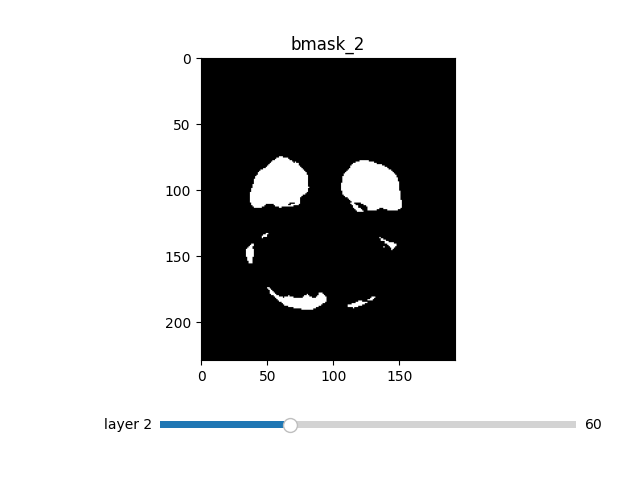

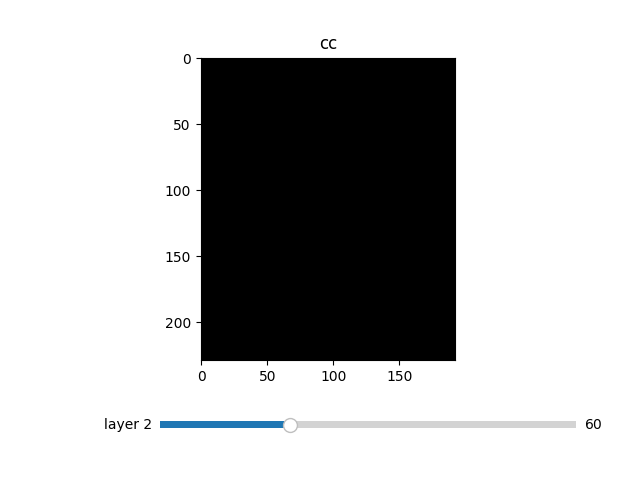

In [16]:
aa = seg_not_cerebellum.copy()
aa[seg_not_cerebellum > 1] = 1
bb = aa.copy()

bmask_2 = nfc.load_nifti(pil.get_patient_image_path_name(hunt, id, f"{id}_{hunt-3}_BMASK_MNI_NOCEREB_{se_1}_{se_2}.nii.gz", absolute=True))[0]
bb[bmask_2 == 0] = 0
cc = aa - bb

print(np.sum(cc))

fc.imgshow_3D("bmask_2", bmask_2, current_plane=60, range_values=(0, 1))
fc.imgshow_3D("cc", cc, current_plane=60, range_values=(0, 1))

